In [1]:
import numpy as np  
import matplotlib.pyplot as plt
import netCDF4 as nc
import torch
import scipy as scp

# LOTUS DATA

In [2]:
class LotusData:
    def __init__(self):
        # --- Files ---
        self._MET_FILE  = '/home/mnex/Desktop/1DV_FD/experiments/LOTUS/obs/lotusmet.epic'
        self._TEMP_FILE = '/home/mnex/Desktop/1DV_FD/experiments/LOTUS/obs/lotusnstemp.epic'
        self._VEL_FILE  = '/home/mnex/Desktop/1DV_FD/experiments/LOTUS/obs/lotusnsvel.epic'

        # --- Parameters of obs ---
        self._DT = 900    # LOTUS sampling (15 min)
        self._NDAYS = 160 # Obs to take [days]
        self._NOBS = self._NDAYS*86400 // self._DT
        
        # --- Time serie ---
        self.t = torch.linspace(0, self._DT*self._NOBS, self._NOBS)

        # --- Meteorological data ---        
        with nc.Dataset(self._MET_FILE, 'r') as f:
            self.wind_u    = torch.tensor(f.variables['wnde'][:self._NOBS, 0, 0, 0])
            self.wind_v    = torch.tensor(f.variables['wndn'][:self._NOBS, 0, 0, 0])
            self.temp_surf = torch.tensor(f.variables['stmp'][:self._NOBS, 0, 0, 0])

        # --- Temperature data ---
        with nc.Dataset(self._TEMP_FILE, 'r') as f:
            self.z     = f.variables['depth'][:self._NOBS]
            self.temp  = f.variables['temp'][:self._NOBS, :, 0, 0]

        # --- Velocity data ---
        with nc.Dataset(self._VEL_FILE, 'r') as f:
            self.u = f.variables['east'][:self._NOBS, :, 0, 0]
            self.v = f.variables['north'][:self._NOBS, :, 0, 0]

    def get_forcing(self, 
                    var_mean: torch.Tensor, 
                    var_std: torch.Tensor,
                    ne: int,
                    nt: int,
                    cplx: bool = True,
                    memory_time: float = 3600*3,
                    ):
        c1 = torch.exp(torch.tensor(-dt / memory_time))
        c2  = torch.sqrt(1.0 - c1**2)

        block_dt = lotus._DT * window_len
        n_blocks = tend // block_dt
        dtype = torch.complex64 if cplx else torch.float32
        
        forcing = torch.zeros(ne, nt, dtype = dtype)
        forcing[:, 0] = var_mean[0]
        for kt in range(1, nt):
            # Index
            t  = kt * dt
            kw = min(t // block_dt, n_blocks - 1)

            rn = torch.randn(ne, dtype = dtype)
            _m = var_mean[kw]
            _s = var_std[kw]
                
            forcing[:, kt] = _m + c1 * (forcing[:, kt-1] - _m) + c2 * _s * rn

        time = torch.linspace(0, tend, nt) / 86400
        return time, forcing
    
    @staticmethod
    def _block_stats(x, window_len):
        n = len(x) // window_len
        blocks = x[:n * window_len].reshape(n, window_len)
        return blocks.mean(1), blocks.std(1)

In [3]:
def plot_var(time, var, ax, label = None, color = 'C0'):
    _m = var.mean(axis = 0)
    _v = var.real.std(axis = 0)
    ax.plot(time, _m, label = label, color = color)
    ax.fill_between(time, _m - _v**0.5, _m + _v**0.5, alpha = 0.3, color = color)

# WIND AND SURFACE FORCING

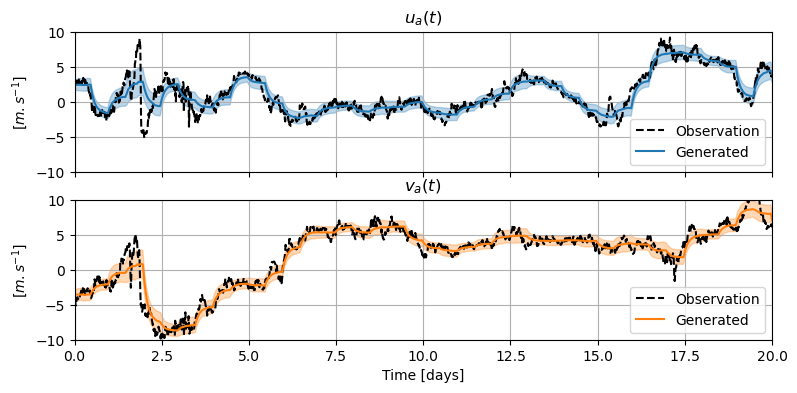

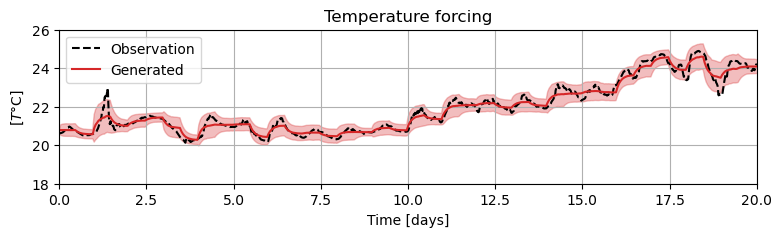

In [4]:
dt = 3600
tend = 3600 * 24 * 160
nt = int(tend / dt)

ne = 1000
wind_Ta = 3600*3
window_len = 48

lotus = LotusData()
t_lotus = lotus.t / 86400

# --- Wind ---
ua_m, ua_s = lotus._block_stats(lotus.wind_u, window_len)
va_m, va_s = lotus._block_stats(lotus.wind_v, window_len)
ua_m = ua_m + 1j*va_m
ua_s = ua_s + 1j*va_s
t_frc, ua_frc = lotus.get_forcing(ua_m, ua_s, ne, nt, cplx = True, memory_time=wind_Ta)

fig, ax = plt.subplots(2, 1, figsize = (9, 4), sharex=True)
ax[0].set_title(r'${u}_a(t)$')
ax[0].plot(t_lotus, lotus.wind_u, 'k--', label = 'Observation')
plot_var(t_frc, ua_frc.real, ax[0], label = 'Generated', color = 'C0')
ax[0].set_ylim(-10, 10)
ax[0].set_xlim(0, 20)
ax[0].set_ylabel(r'[$m.s^{-1}$]')
ax[0].grid()
ax[0].legend()

ax[1].set_title(r'${v}_a(t)$')
ax[1].plot(t_lotus, lotus.wind_v, 'k--', label = 'Observation')
plot_var(t_frc, ua_frc.imag, ax[1], label = 'Generated', color = 'C1')
ax[1].set_ylim(-10, 10)
ax[1].set_xlim(0, 20)
ax[1].set_ylabel(r'[$m.s^{-1}$]')
ax[1].set_xlabel('Time [days]')
ax[1].grid()
ax[1].legend()


# --- Surface temp ---
Ts_m, Ts_s = lotus._block_stats(lotus.temp_surf, window_len)
t_frc, Ts_frc = lotus.get_forcing(Ts_m, Ts_s, ne, nt, cplx = False, memory_time=wind_Ta)

fig, ax = plt.subplots(1, 1, figsize = (9, 2))
ax.set_title(r'Temperature forcing')
ax.plot(t_lotus, lotus.temp_surf, 'k--', label = 'Observation')
plot_var(t_frc, Ts_frc, ax, label = 'Generated', color = 'C3')
ax.set_ylim(18, 26)
ax.set_xlim(0, 20)
ax.set_ylabel(r'[$T$°C]')
ax.set_xlabel('Time [days]')
ax.grid()
ax.legend()


# MLD DIagnostic

In [5]:
def get_brunt_vaisala(T, z):
    # Shape of T: (nt, nz), z: (nz)
    rho_o = 1000
    g = 9.81
    S=38
    eos_T0 = 20   # Reference temperature (°C)
    eos_S0 = 38   # Reference Salinity (PSU)
    beta_T = 2e-4 # Thermal expansion coefficient
    beta_S = 1e-3 # Haline contraction coefficient

    rho = rho_o * ((1 - beta_T * (T - eos_T0)) + beta_S * (S - eos_S0))
    N2 = g / rho_o * (rho[:, 1:] - rho[:, :-1]) / (z[1:] - z[:-1])
    return N2

def get_MLD(N2, z, tresh = 3e-4):
    # Compute MLD as max(N2) if > treshold
    nt, _ = N2.shape

    mld = np.zeros(nt)
    mld[0] = z[0]
    for kt in range(1, nt):
        if np.max(N2[kt]) > tresh:
            idx = np.argmax(N2[kt]) + 1
            mld[kt] = z[idx]
        else:
            mld[kt] = z[0] #mld[kt-1]
    return mld

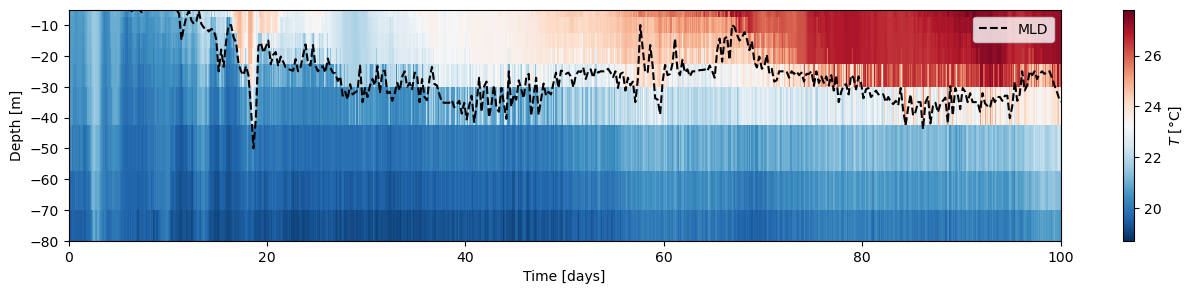

In [6]:
z = lotus.z
t = lotus.t / 86400
temp = lotus.temp

N2 = get_brunt_vaisala(lotus.temp, lotus.z)
mld = get_MLD(N2, lotus.z, tresh = 2e-4)

# Average on window (SIZE OF WINDOW TO CHOOSE)
window = 24
nt, nobs = temp.shape
n_win = nt // window
mld_ave = mld[:n_win * window].reshape(n_win, window).mean(axis=1)
t_ave = (np.arange(n_win) + 0.5) * window * 900 / 86400

plt.figure(figsize=(16, 3))
plt.xlabel('Time [days]')
plt.ylabel('Depth [m]')
plt.pcolormesh(t, -z, temp.T, cmap = 'RdBu_r')
plt.plot(t_ave, -mld_ave, 'k--', label = 'MLD')
plt.xlim(0, 100)
plt.ylim(-80, -5)
plt.colorbar(label = r'$T$ [°C]')
plt.legend()

In [7]:
def plot_MLD_model(model_name, ne, label = None, color = 'C0', window_ave = 24):
    OUTPUT_FOLDER = '/home/mnex/Desktop/1DV_FD/experiments/LOTUS/output/'
    file_name = OUTPUT_FOLDER + f'lotus_stratif_{model_name}_ne{ne}.nc'
    
    with nc.Dataset(file_name) as data:
        t   = data['time'][:]
        mld_m  = -data[f'mld_mean'][:]
        mld_v  = data[f'mld_var'][:]
    
    # --- Window averaging ---
    nt = mld_m.shape[0]
    dt = t[1] - t[0]
    n_win = nt // window_ave
    mld_m_ave = mld_m[:n_win * window_ave].reshape(n_win, window_ave).mean(axis=1)
    mld_v_ave = mld_v[:n_win * window_ave].reshape(n_win, window_ave).mean(axis=1)
    t_ave = (np.arange(n_win) + 0.5) * window_ave * dt / 86400
    
    plt.plot(t_ave, mld_m_ave, label = label, color = color)
    plt.fill_between(t_ave,
                     mld_m_ave + mld_v_ave**0.5, 
                     mld_m_ave - mld_v_ave**0.5, 
                     color = color, alpha = 0.2)

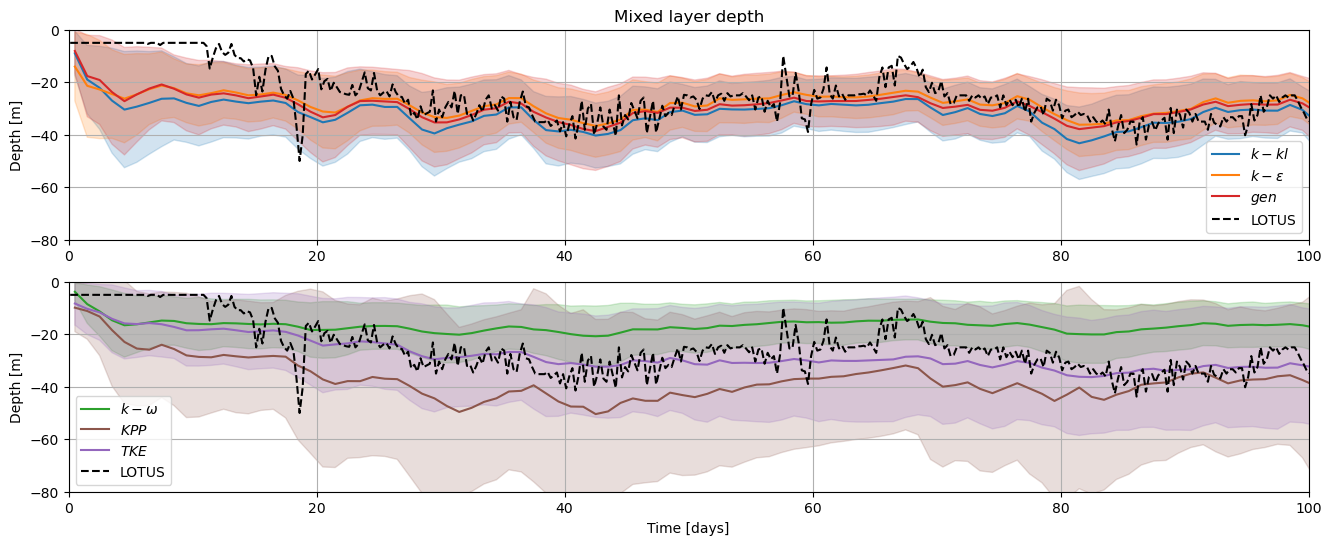

In [8]:
plt.figure(figsize=(16, 6))

plt.subplot(211)
plt.title('Mixed layer depth')
plt.ylabel('Depth [m]')

# Model
plot_MLD_model('k-kl',      1000, r'$k-kl$',          'C0', window_ave = window)
plot_MLD_model('k-epsilon', 1000, r'$k-\varepsilon$', 'C1', window_ave = window)
plot_MLD_model('gen',       1000, r'$gen$',           'C3', window_ave = window)

# REF
plt.plot(t_ave, -mld_ave, 'k--', label = 'LOTUS')
plt.xlim(0, 100)
plt.ylim(-80, 0)
plt.legend()
plt.grid()

plt.subplot(212)
plt.xlabel('Time [days]')
plt.ylabel('Depth [m]')

plot_MLD_model('k-omega',   1000, r'$k-\omega$',      'C2')
plot_MLD_model('kpp',       1000, r'$KPP$',           'C5')
plot_MLD_model('tke',       1000, r'$TKE$',           'C4')

# REF
plt.plot(t_ave, -mld_ave, 'k--', label = 'LOTUS')
plt.xlim(0, 100)
plt.ylim(-80, 0)
plt.legend()
plt.grid()

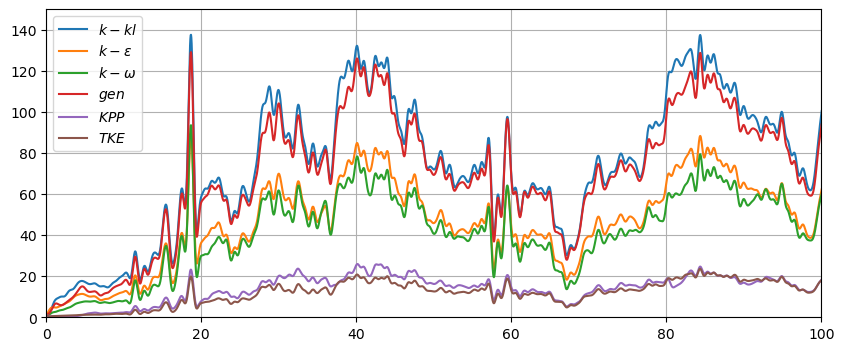

In [ ]:
def make_window_ave(array, window_len):
    n_win = array.shape[0] // window_len
    return array[:n_win * window_len].reshape(n_win, window_len).mean(axis=1)


def plot_forecast_model(model_name, label = None):
    OUTPUT_FOLDER_MODEL = '/home/mnex/Desktop/1DV_FD/experiments/LOTUS/output/'
    file_name = OUTPUT_FOLDER_MODEL + f'lotus_stratif_{model_name}_ne{ne}.nc'
    
    with nc.Dataset(file_name) as data:
        time   = data['time'][1:] / 86400
        mld_m  = -data[f'mld_mean'][1:]
        mld_v  = data[f'mld_var'][1:]

    lotus = LotusData()
    N2_lotus = get_brunt_vaisala(lotus.temp, lotus.z)
    mld_lotus = make_window_ave(get_MLD(N2, lotus.z, tresh = 2e-4), 4)
        
    # --- MSE and VAR ---
    MSE = (mld_m - mld_lotus)**2
    VAR = mld_v

    # --- Forecast score ---
    cff = (ne + 1) / (ne-1)
    EPS = np.abs(MSE - cff * VAR)
    EPS /= EPS[0]

    # --- Filtering ---
    t_days = time
    dt = t_days[1] - t_days[0] # days
    fs = 1./dt                 # samp. freq.
    fc = 1.                    # cutoff freq. (1/days)
    wid = fc/(fs/2)
    num_filt, denom_filt = scp.signal.butter(5, wid, 'low')
    forecast = scp.signal.filtfilt(num_filt, denom_filt, EPS)

    plt.plot(t_days, forecast, label = label)    
    
plt.figure(figsize = (10, 4))
plot_forecast_model('k-kl',      r'$k-kl$')
plot_forecast_model('k-epsilon', r'$k-\varepsilon$')
plot_forecast_model('k-omega',   r'$k-\omega$')
plot_forecast_model('gen',       r'$gen$')
plot_forecast_model('kpp',       r'$KPP$')
plot_forecast_model('tke',       r'$TKE$')
plt.xlim(0, 100)
plt.ylim(0, 150)
plt.grid()
plt.legend()